# 检索基线与候选召回

BM25、语义后端和 RRF 使用结果清单中的实际参数。LSA 是语料拟合的潜在语义基线；只有 neural_encoder=true 才属于神经向量检索。

In [1]:
from pathlib import Path
import json, sys, os
import pandas as pd
from IPython.display import display, Image
root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'project/src/ragstudy').is_dir())
for folder in ('.vendor', '.vendor-hf', '.vendor-onnx-compat'):
    path = root / 'project' / folder
    if path.is_dir():
        sys.path.insert(0, str(path))
sys.path.insert(0, str(root / 'project/src'))
artifacts = sorted(path for path in (root / 'project/artifacts').iterdir()
                   if (path / 'results.json').is_file() and (path / 'search_bundle.joblib').is_file())
assert artifacts, 'First run python project/scripts/run_experiment.py --backend lsa'
artifact = Path(os.environ['RAG_ARTIFACT']).resolve() if os.environ.get('RAG_ARTIFACT') else artifacts[-1]
result = json.loads((artifact / 'results.json').read_text(encoding='utf-8'))
print('Actual local run:', artifact.name, '| backend:', result['retrieval_metadata']['semantic']['method'])

Actual local run: frozen_e2324b7a967c5dbe2766ecc3 | backend: frozen_onnx_fp32_cls_cosine


In [2]:
display(result['retrieval_metadata'])
display(pd.DataFrame(result['summary']['dev']['methods']).T.loc[['bm25','semantic','rrf']])
print('Union candidate recall:', result['summary']['dev']['candidate_recall'])

{'bm25': {'method': 'bm25',
  'k1': 1.2,
  'b': 0.75,
  'idf': 'log(1 + (N - df + 0.5) / (df + 0.5))',
  'query_term_frequency': 'linear',
  'documents': 28478,
  'vocabulary_size': 231710,
  'average_document_tokens': 242.49497985839844,
  'tokenizer': '[a-z0-9_]+(?:[.+#:/\\\\-][a-z0-9_]+)*[+#]*'},
 'semantic': {'method': 'frozen_onnx_fp32_cls_cosine',
  'neural_encoder': True,
  'local_model_path': 'D:\\Users\\hyy\\Desktop\\guideline\\course\\5001\\project\\models\\bge-small-en-v1.5',
  'local_files_only': True,
  'model_onnx_sha256': '828e1496d7fabb79cfa4dcd84fa38625c0d3d21da474a00f08db0f559940cf35',
  'model_revision': '5c38ec7c405ec4b44b94cc5a9bb96e735b38267a',
  'pinned_onnx_download_manifest': {'model': 'BAAI/bge-small-en-v1.5',
   'revision': '5c38ec7c405ec4b44b94cc5a9bb96e735b38267a',
   'files': [{'path': 'onnx/model.onnx',
     'bytes': 133093490,
     'sha256': '828e1496d7fabb79cfa4dcd84fa38625c0d3d21da474a00f08db0f559940cf35',
     'upstream_lfs_sha256_verified': True,
   

,ndcg@10,recall@20
bm25,0.599669,0.690476
semantic,0.686528,0.797619
rrf,0.656692,0.797619


Union candidate recall: 0.9285714285714286


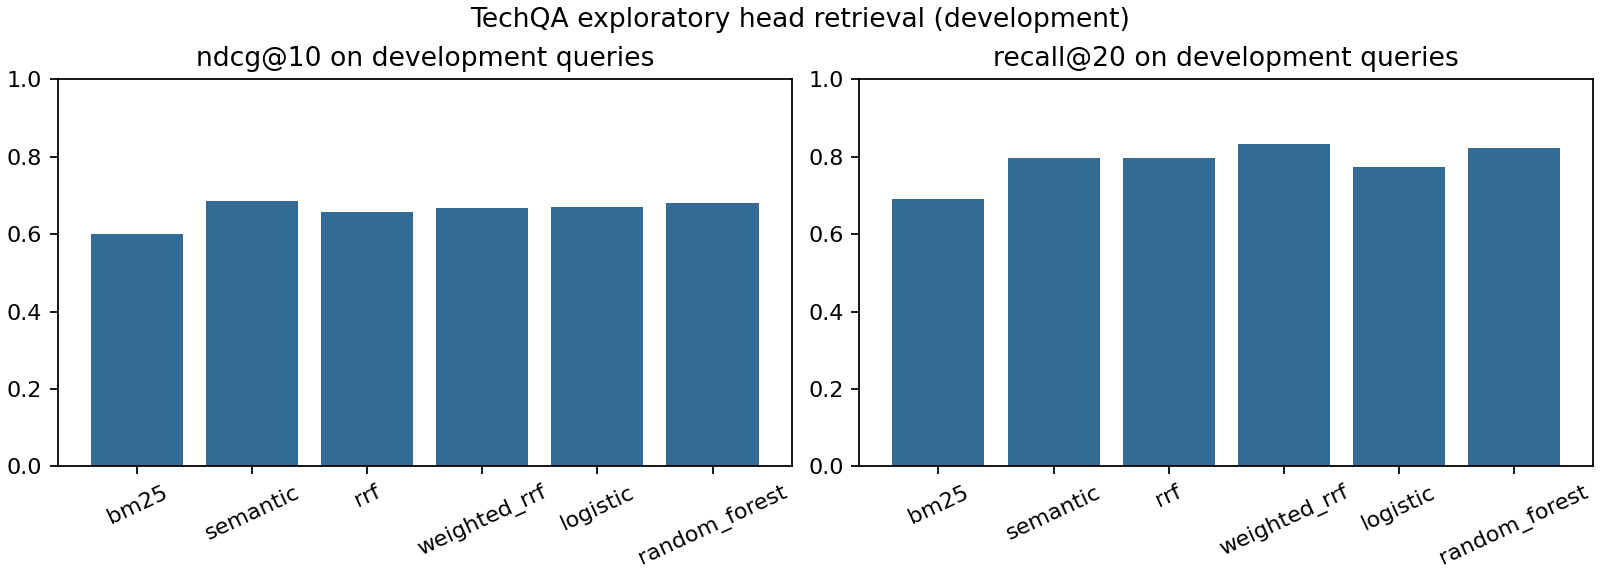

Input heads: 256 words; long-document evidence can be lost.


In [3]:
display(Image(filename=str(artifact / 'development_metrics.png')))
print('Input heads:', result['data_audit']['head_words'], 'words; long-document evidence can be lost.')